# The system: four equal atomic balls

**Question:** can a probe fit inside a tetrahedral gap while being too large
to pass through any of its triangular faces?

This notebook defines the input and the independent expectations. It uses
NumPy geometry and PyUnitWizard quantities; it does not import or execute
DFND. Read [the case overview](index.md), then continue with the separate
[DFND experiments](dfnd.ipynb).

The model consists of four fictitious atomic balls at the vertices of a
regular tetrahedron: edge **5.3 Å**, common atomic radius **1.7 Å**, no jitter
and no periodicity. The balls are a geometric model, not a protein.

Run all cells from this case directory in a fresh kernel. The frozen input
is read without modification; no server or original provider is contacted.
Downloads: {download}`quantity-aware input <artifacts/regular_tetrahedron_v1/input.json>`
and {download}`historical PDB export <artifacts/regular_tetrahedron_v1/input.pdb>`.

In [1]:
import hashlib
import html
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyunitwizard as puw
from IPython.display import Markdown, display
from pyunitwizard import QuantityRecord

input_path = Path('artifacts/regular_tetrahedron_v1/input.json')
input_bytes = input_path.read_bytes()
fixture = json.loads(input_bytes)


def quantity(field):
    return QuantityRecord.from_dict(fixture[field]).to_quantity(
        field=field, unit='angstroms'
    )


def values(field):
    return np.asarray(puw.get_value(quantity(field), to_unit='angstroms'))


def qrecord(value, unit, field):
    return QuantityRecord.from_quantity(
        puw.quantity(value, unit), field=field
    ).to_dict()


coords = values('coordinates')
radii = values('atom_radii')
edge = float(values('edge'))
probes = values('anchor_probes')
atol = fixture['reference']['clearance_atol_angstroms']
volume_rtol = fixture['reference']['cell_volume_rtol']
assert coords.shape == (4, 3)
np.testing.assert_array_equal(radii, np.full(4, 1.7))
pair_distances = np.array([
    np.linalg.norm(coords[i] - coords[j])
    for i in range(4) for j in range(i)
])
np.testing.assert_allclose(pair_distances, edge, rtol=0, atol=atol)
np.testing.assert_array_equal(probes, [1.2, 1.4, 1.7])
display(Markdown(
    '| Ball | x (Å) | y (Å) | z (Å) | Radius (Å) |\n'
    '|---|---:|---:|---:|---:|\n' + '\n'.join(
        f'| {chr(65+i)} | {point[0]:.6f} | {point[1]:.6f} | '
        f'{point[2]:.6f} | {radii[i]:.1f} |'
        for i, point in enumerate(coords)
    )
))

| Ball | x (Å) | y (Å) | z (Å) | Radius (Å) |
|---|---:|---:|---:|---:|
| A | 1.873833 | 1.873833 | 1.873833 | 1.7 |
| B | 1.873833 | -1.873833 | -1.873833 | 1.7 |
| C | -1.873833 | 1.873833 | -1.873833 | 1.7 |
| D | -1.873833 | -1.873833 | 1.873833 | 1.7 |

## Inspect the actual input

The transparent surfaces below are the atomic balls. Dashed edges join their
centers and show the finite tetrahedron; they are not physical walls.
The blue point is the tetrahedron center and orange points are face centers.
The table rounds coordinates for reading; the JSON retains full precision.

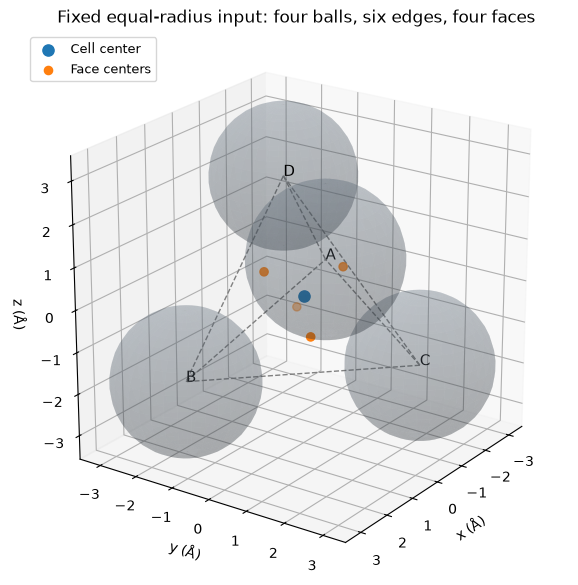

In [2]:
center = coords.mean(axis=0)
face_centers = np.array([np.delete(coords, i, axis=0).mean(axis=0) for i in range(4)])
azimuth = np.linspace(0, 2*np.pi, 36)
polar = np.linspace(0, np.pi, 22)
sphere = np.array([
    np.outer(np.cos(azimuth), np.sin(polar)),
    np.outer(np.sin(azimuth), np.sin(polar)),
    np.outer(np.ones_like(azimuth), np.cos(polar)),
])
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
for i, point in enumerate(coords):
    ax.plot_surface(*(point[:, None, None] + radii[i]*sphere),
                    color='slategray', alpha=0.22, linewidth=0)
    ax.text(*point, chr(65+i), fontsize=11)
    for other in coords[:i]:
        ax.plot(*np.stack([point, other]).T, '--', color='gray', linewidth=1)
ax.scatter(*center, color='tab:blue', s=65, label='Cell center')
ax.scatter(*face_centers.T, color='tab:orange', s=35, label='Face centers')
limit = float(np.max(np.abs(coords-center)) + radii.max())
ax.set(xlim=(center[0]-limit, center[0]+limit),
       ylim=(center[1]-limit, center[1]+limit),
       zlim=(center[2]-limit, center[2]+limit),
       xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)')
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=22, azim=35)
ax.legend(loc='upper left', fontsize=9)
ax.set_title('Fixed equal-radius input: four balls, six edges, four faces')
fig.tight_layout()
plt.show()

## Independent expectations

A probe of radius $r_p$ can place its center at a point $x$ only when
$\|x-x_i\|\geq r_a+r_p$ for every atomic center $x_i$. Equivalently, we study
the free space between balls expanded by the probe radius. The atoms stay fixed.

For this symmetric equal-radius input, tetrahedron and equilateral-triangle
circumradius formulas give the two reference clearances:

$$R_\mathrm{res}=\frac{a\sqrt{6}}4-r_a,\qquad
R_\mathrm{face}=\frac{a}{\sqrt3}-r_a.$$

The first measures room for a probe inside the finite cell; the second
measures passage through one of its closed triangular faces. They are
distinct geometric quantities. The fourth atom does not reduce the face
center's clearance in this regular configuration.

The finite hull volume is $V_\mathrm{hull}=a^3/(6\sqrt2)$. It includes pieces
of the atomic balls and is not an atom-free or probe-accessible volume.
We also check it using the coordinate determinant, without constructing a
DFND mesh.

In [3]:
residence = float(edge*np.sqrt(6)/4 - radii[0])
face = float(edge/np.sqrt(3) - radii[0])
hull_volume = float(edge**3/(6*np.sqrt(2)))
coordinate_volume = abs(float(np.linalg.det(coords[1:] - coords[0])))/6
np.testing.assert_allclose(coordinate_volume, hull_volume, rtol=volume_rtol)
center_clearance = float(np.min(np.linalg.norm(coords-center, axis=1)-radii))
face_clearances = np.min(
    np.linalg.norm(face_centers[:, None, :] - coords[None, :, :], axis=2)
    - radii[None, :], axis=1
)
np.testing.assert_allclose(center_clearance, residence, rtol=0, atol=atol)
np.testing.assert_allclose(face_clearances, face, rtol=0, atol=atol)
display(Markdown(
    '| Independent quantity | Value |\n|---|---:|\n'
    f'| Residence clearance | {residence:.9f} Å |\n'
    f'| Face clearance | {face:.9f} Å |\n'
    f'| Finite hull volume | {hull_volume:.9f} Å³ |'
))

| Independent quantity | Value |
|---|---:|
| Residence clearance | 1.545573909 Å |
| Face clearance | 1.359956427 Å |
| Finite hull volume | 17.545322710 Å³ |

## Three preselected experiments

Only the probe radius changes. The 1.2 Å probe is below both clearances;
the 1.4 Å probe fits inside but exceeds every face clearance; the 1.7 Å
probe exceeds the residence clearance. These values are deliberately away
from equality, so this study does not decide epsilon behavior at a threshold.

We fix clearance absolute tolerance at **1e-6 Å**, zero relative tolerance,
and hull-volume relative tolerance at **1e-12**, using the frozen input's
declared criteria. These are not accuracy bounds for a solvent-volume estimate.

| Probe (Å) | Expected residence | Permeable faces | Interpretation |
|---:|---|---:|---|
| 1.2 | True | 4 | Room inside and through the faces |
| 1.4 | True | 0 | Room inside; faces sealed to this probe |
| 1.7 | False | 0 | No room for this probe inside the finite cell |

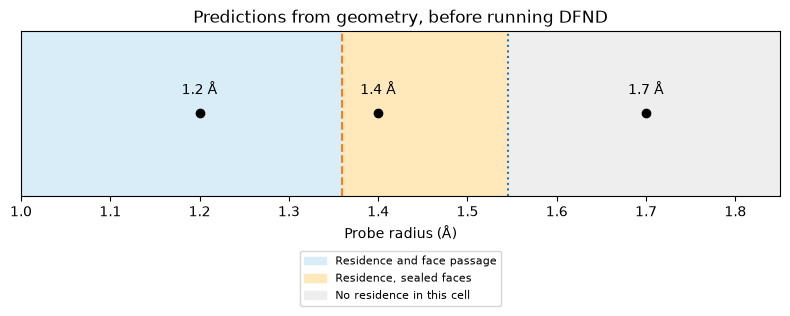

In [4]:
experiments = []
for probe in probes:
    assert min(abs(probe-residence), abs(probe-face)) > 10*atol
    resident = bool(probe < residence)
    permeable_faces = 4 if probe < face else 0
    meaning = (
        'Room inside and through the faces' if permeable_faces else
        'Room inside; faces sealed to this probe' if resident else
        'No room for this probe inside the finite cell'
    )
    experiments.append({
        'probe_radius': qrecord(float(probe), 'angstroms', 'probe_radius'),
        'resident': resident, 'permeable_faces': permeable_faces, 'meaning': meaning,
    })
display(Markdown(
    '| Probe (Å) | Expected residence | Permeable faces | Interpretation |\n'
    '|---:|---|---:|---|\n' + '\n'.join(
        f"| {probe:.1f} | {row['resident']} | {row['permeable_faces']} | {row['meaning']} |"
        for probe, row in zip(probes, experiments)
    )
))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(0, face, color='#d8edf7', label='Residence and face passage')
ax.axvspan(face, residence, color='#ffe9ba', label='Residence, sealed faces')
ax.axvspan(residence, 1.9, color='#eeeeee', label='No residence in this cell')
ax.axvline(face, color='tab:orange', linestyle='--')
ax.axvline(residence, color='tab:blue', linestyle=':')
for i, probe in enumerate(probes):
    ax.plot(probe, 0.5, 'o', color='black')
    ax.annotate(f'{probe:.1f} Å', (probe, 0.5), xytext=(0, 14),
                textcoords='offset points', ha='center')
ax.set(xlim=(1.0, 1.85), ylim=(0, 1), yticks=[], xlabel='Probe radius (Å)',
       title='Predictions from geometry, before running DFND')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), fontsize=8)
fig.tight_layout()
plt.show()

## What these expectations do and do not establish

This reference fixes symmetric local clearances, finite hull volume and
three nonmarginal probe regimes. It does not certify an exact solvent volume,
establish a general continuous-path algorithm, or validate biological pockets.
Four permeable faces are also not automatically four independently identified
physical mouths; exterior grouping is inspected in the DFND study.

The PDB export rounds coordinates and cannot encode the explicit atomic
radii. Both new notebooks therefore use the same full-precision JSON input.
Comparator-specific exports will be discussed in the future comparison stage.

In [5]:
reference_report = {
    'schema': 'topomt.benchlab.system-reference/1',
    'case_id': fixture['case_id'], 'case_version': fixture['case_version'],
    'input_sha256': hashlib.sha256(input_bytes).hexdigest(),
    'model': fixture['model'], 'radius_policy': fixture['radius_policy'],
    'reference': {
        'residence_clearance': qrecord(residence, 'angstroms', 'residence_clearance'),
        'face_clearance': qrecord(face, 'angstroms', 'face_clearance'),
        'cell_hull_volume': qrecord(hull_volume, 'angstroms**3', 'cell_hull_volume'),
    },
    'tolerances': {
        'clearance_absolute': qrecord(atol, 'angstroms', 'clearance_absolute'),
        'clearance_relative': 0.0, 'hull_volume_relative': volume_rtol,
    },
    'experiments': experiments, 'reference_checks': 'passed',
    'limits': ['Symmetric equal-radius geometry only', 'No solvent-volume precision claim',
               'No general continuous navigability or biological-site claim'],
}
text = json.dumps(reference_report, indent=2, allow_nan=False)
display({'text/plain': text,
         'text/html': '<details><summary>Complete independent reference</summary><pre>'
                      + html.escape(text) + '</pre></details>'}, raw=True)

{
  "schema": "topomt.benchlab.system-reference/1",
  "case_id": "regular_tetrahedron",
  "case_version": 1,
  "input_sha256": "8634f70afdaf21cb8388887f5f80ae73dc36ef4f043198a10b525a93ebde5ce3",
  "model": "Four non-overlapping equal-radius atomic balls; nonperiodic Cartesian geometry.",
  "radius_policy": "Explicit 1.7 angstrom radii, carbon-like geometric choice; not inferred from PDB.",
  "reference": {
    "residence_clearance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "residence_clearance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 1.5455739091877108,
      "block_digests": [
        "blake2b-128:e5acadba832509bd5d3177f2a0b35df8"
      ],
      "digest": "blake2b-128:80f203fb8264dbea1f1cee111b60a046"
    },
    "face_clearance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "face_clearance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 1.3599564267050168,
      "block_digests": [
        "blake2b-128:bf51d665770775e14b7a1f9101b377c6"
      ],
      "digest": "blake2b-128:42fad3f667ade5bf8dd197f16c728487"
    },
    "cell_hull_volume": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "cell_hull_volume",
        "unit": "angstrom ** 3",
        "si": {
          "factor": 1e-30,
          "offset": 0.0,
          "exponents": {
            "m": 3
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 17.5453227104516,
      "block_digests": [
        "blake2b-128:d28c0304bfcb5509f108f755f3acbd3f"
      ],
      "digest": "blake2b-128:ca3329b87e34408b6bca63d96ff2a05a"
    }
  },
  "tolerances": {
    "clearance_absolute": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "clearance_absolute",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 1e-06,
      "block_digests": [
        "blake2b-128:fdc4aee404c6c8d3af6c444a146a42d5"
      ],
      "digest": "blake2b-128:10a5cf83a846c84bb5e68a5256c7b223"
    },
    "clearance_relative": 0.0,
    "hull_volume_relative": 1e-12
  },
  "experiments": [
    {
      "probe_radius": {
        "manifest": {
          "format": "qrec/0.3",
          "field": "probe_radius",
          "unit": "angstrom",
          "si": {
            "factor": 1e-10,
            "offset": 0.0,
            "exponents": {
              "m": 1
            }
          },
          "dtype": "float64",
          "shape": [],
          "blocks": [
            1
          ]
        },
        "values": 1.2,
        "block_digests": [
          "blake2b-128:7f818a45feb71a60cf3effd121324813"
        ],
        "digest": "blake2b-128:8ad14c1a9de655527fbef89a4dc29b85"
      },
      "resident": true,
      "permeable_faces": 4,
      "meaning": "Room inside and through the faces"
    },
    {
      "probe_radius": {
        "manifest": {
          "format": "qrec/0.3",
          "field": "probe_radius",
          "unit": "angstrom",
          "si": {
            "factor": 1e-10,
            "offset": 0.0,
            "exponents": {
              "m": 1
            }
          },
          "dtype": "float64",
          "shape": [],
          "blocks": [
            1
          ]
        },
        "values": 1.4,
        "block_digests": [
          "blake2b-128:ff

The reviewed reference is downloadable as
{download}`system_reference.json <artifacts/native_study_v1/system_reference.json>`.
This notebook displays a newly computed reference in memory and does not
overwrite that file. Continue with [DFND](dfnd.ipynb), which reads the committed
reference and input directly and can run in its own fresh kernel.